# Week 9: Gradient Boosting
**Capstone project:** Predicting Health Risk and Diabetes Status from Lifestyle and Survey Data | Komal Misra

Gradient boosting builds an ensemble of small decision trees **one at a time**. Each new tree (a "weak learner") is fit to the errors the ensemble still makes, and only a fraction of its correction, set by the **learning rate**, is added. This notebook works through the method by hand, compares it with random forest, and then tunes it on both project datasets:

- **Dataset B:** CDC BRFSS 2015 diabetes indicators (253,680 rows, 21 survey features). Diabetes and prediabetes are collapsed into one positive class.
- **Dataset A:** Health & Lifestyle dataset (100,000 rows). Targets are `disease_risk` and BMI.

**Sections**
1. Setup and data
2. Gradient boosting by hand
3. Gradient boosting vs. random forest
4. Learning rate and number of trees
5. Tree depth
6. Regularization
7. Tuning with early stopping and grid search
8. Final model on the test set
9. Does more data help? Full BRFSS
10. Dataset A
11. Summary

## 1. Setup and data

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor, RandomForestClassifier,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, log_loss, f1_score, precision_score, recall_score,
                             accuracy_score, precision_recall_curve, r2_score)

warnings.filterwarnings('ignore')
SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3})
BLUE, ORANGE, GREEN, VIOLET, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#6250d6', '#8a8984'

In [2]:
brfss = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')
life = pd.read_csv('health_lifestyle_dataset.csv')
brfss['diabetes'] = (brfss['Diabetes_012'] > 0).astype(int)
X_all = brfss.drop(columns=['Diabetes_012', 'diabetes']); y_all = brfss['diabetes']
print('BRFSS:', brfss.shape, f"| prevalence {y_all.mean():.1%}", '| Lifestyle:', life.shape)

BRFSS: (253680, 23) | prevalence 15.8% | Lifestyle: (100000, 16)


I use the same design as earlier weeks: a **50,000-row stratified sample** of BRFSS and an **80/20 stratified train/test split** (seed 42). The 10,000-row test set stays untouched until Section 8. For the learning-curve experiments in Sections 3–6, I split the training set again into a 32,000-row fitting set and an 8,000-row **validation** set, so I can watch performance on unseen data after every tree.

In [3]:
X, _, y, _ = train_test_split(X_all, y_all, train_size=50_000, stratify=y_all, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
print('fit', X_fit.shape, '| validation', X_val.shape, '| test', X_test.shape)

fit (32000, 21) | validation (8000, 21) | test (10000, 21)


**Metrics.** With 15.8% prevalence, accuracy is misleading (predicting "no diabetes" for everyone scores about 84%). I track **log loss** (how close predicted probabilities are to the true labels; the quantity boosting actually minimizes) and **ROC AUC** (how well the model ranks diabetic respondents above non-diabetic ones). I choose a classification cutoff separately in Section 8.

## 2. Gradient boosting by hand
### 2a. The three-house example
The reading's example: three houses sold for 1.8, 1.3 and 2.6 (hundreds of thousands). Boosting starts from a constant prediction (the mean, 1.9), fits a stump to the residuals, and adds a learning-rate-scaled share of the stump's prediction.

In [4]:
actual = np.array([1.8, 1.3, 2.6])
color = np.array([[0], [0], [1]])            # feature: 0 = "orange", 1 = "blue"
lr = 0.5

pred = np.full(3, actual.mean())
table = {'actual': actual, 'step 0 prediction': pred.copy(), 'step 0 residual': actual - pred}
for step in [1, 2, 3]:
    stump = DecisionTreeRegressor(max_depth=1).fit(color, actual - pred)
    pred = pred + lr * stump.predict(color)
    table[f'step {step} prediction'] = pred.copy()
    table[f'step {step} residual'] = actual - pred
pd.DataFrame(table, index=['house 1 (orange)', 'house 2 (orange)', 'house 3 (blue)']).T.round(3)

,house 1 (orange),house 2 (orange),house 3 (blue)
actual,1.800,1.300,2.600
step 0 prediction,1.900,1.900,1.900
step 0 residual,-0.100,-0.600,0.700
step 1 prediction,1.725,1.725,2.250
step 1 residual,0.075,-0.425,0.350
step 2 prediction,1.638,1.638,2.425
step 2 residual,0.162,-0.338,0.175
step 3 prediction,1.594,1.594,2.512
step 3 residual,0.206,-0.294,0.087


The first stump splits on color, as in the reading. Because houses 1 and 2 share a color, it predicts their average residual for both (−0.35); the reading uses −0.4 for illustration. Each round, the residuals shrink by half (the learning rate) for the blue house, and the two orange houses converge to their shared average of 1.55. A stump on this one feature can never separate them, which is exactly why boosting adds more trees and more features.

### 2b. A from-scratch booster on BRFSS
The same loop, applied to diabetes: start from the overall prevalence, then repeatedly fit a stump to the residuals (diabetic = 1 minus current prediction) and add 0.1 × its prediction. With squared-error loss, this is exactly what scikit-learn's `GradientBoostingRegressor` does, so I check that the two match.

In [5]:
def boost_by_hand(X, y, n_trees=200, lr=0.1, depth=1):
    pred = np.full(len(y), y.mean()); trees = []
    for _ in range(n_trees):
        t = DecisionTreeRegressor(max_depth=depth, random_state=SEED).fit(X, y - pred)
        pred += lr * t.predict(X); trees.append(t)
    return y.mean(), trees

def predict_by_hand(model, X, lr=0.1):
    base, trees = model
    return base + lr * np.sum([t.predict(X) for t in trees], axis=0)

t0 = time.time()
mine = boost_by_hand(X_fit, y_fit.values.astype(float))
p_mine = predict_by_hand(mine, X_val)
sk = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=1, random_state=SEED).fit(X_fit, y_fit)
p_sk = sk.predict(X_val)
print(f'{time.time()-t0:.0f}s')
print(f'Validation AUC, by hand:      {roc_auc_score(y_val, p_mine):.4f}')
print(f'Validation AUC, scikit-learn: {roc_auc_score(y_val, p_sk):.4f}')
print(f'Largest difference between the two predictions: {np.abs(p_mine - p_sk).max():.2e}')

3s
Validation AUC, by hand:      0.8092
Validation AUC, scikit-learn: 0.8092
Largest difference between the two predictions: 2.83e-15


The hand-built loop reproduces scikit-learn to rounding error. The first few stumps are worth inspecting, since each one picks the single split that best explains what is still unexplained:

In [6]:
rows = []
for i, t in enumerate(mine[1][:8]):
    f, thr = X_fit.columns[t.tree_.feature[0]], t.tree_.threshold[0]
    left, right = t.tree_.value[1][0][0], t.tree_.value[2][0][0]
    rows.append({'stump': i + 1, 'split': f'{f} <= {thr:.1f}', 'residual if yes': left, 'residual if no': right})
pd.DataFrame(rows).set_index('stump').round(4)

,split,residual if yes,residual if no
stump,,,
1,HighBP <= 0.5,-0.0858,0.1146
2,GenHlth <= 2.5,-0.0880,0.0996
3,HighBP <= 0.5,-0.0750,0.1002
4,GenHlth <= 3.5,-0.0381,0.1841
5,GenHlth <= 2.5,-0.0732,0.0828
6,HighBP <= 0.5,-0.0641,0.0856
7,GenHlth <= 3.5,-0.0318,0.1539
8,HighBP <= 0.5,-0.0564,0.0754


The first stump splits on high blood pressure, the second on general health, and the early stumps keep alternating between those two. Because each stump has only one split and only 10% of its correction is kept, the same strong split is reused many times, each time removing a further slice of the remaining error. The corrections get smaller as that error shrinks, and other features enter once these two splits stop being the best available.

For classification, scikit-learn's `GradientBoostingClassifier` uses the same idea but fits trees to the gradient of **log loss** on the log-odds scale rather than to raw residuals. The rest of the notebook uses the classifier.

## 3. Gradient boosting vs. random forest
Both are ensembles of decision trees, and both get their accuracy from combining many trees rather than relying on one. The difference is how the trees are built:

| | Random forest | Gradient boosting |
|---|---|---|
| Tree order | Independent, can be built in parallel | Sequential; each tree depends on the ones before |
| What each tree fits | The original target (on a bootstrap sample) | The errors left by the current ensemble |
| Typical tree | Deep, low bias, high variance | Shallow (stumps to depth ~5), high bias |
| How trees combine | Average | Learning-rate-weighted sum |
| Effect of adding trees | Validation error levels off | Validation error falls, then can rise (overfitting) |

The last row is easiest to see by tracking validation performance as trees are added:

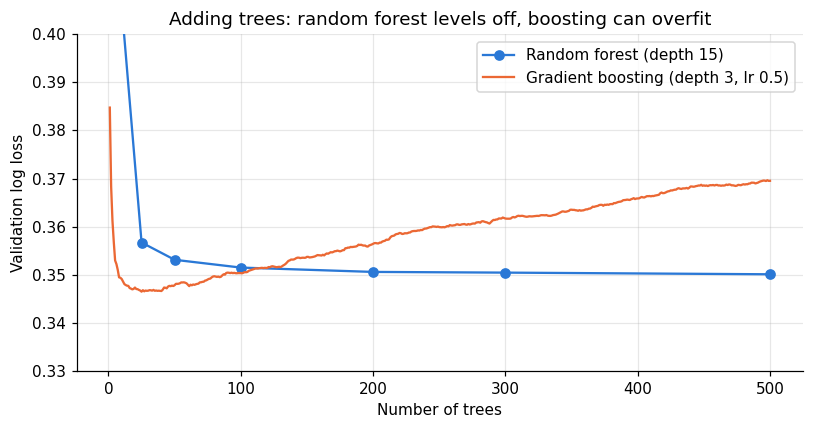

Random forest: best val log loss 0.3501, AUC 0.8078 (2s for all sizes)
Gradient boosting: best val log loss 0.3465 at tree 25, 0.3695 after 500 trees (8s)


In [7]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=500, max_depth=15, n_jobs=-1, random_state=SEED, warm_start=True)
rf_curve, rf_sizes = [], [10, 25, 50, 100, 200, 300, 500]
for n in rf_sizes:
    rf.set_params(n_estimators=n).fit(X_fit, y_fit)
    rf_curve.append(log_loss(y_val, rf.predict_proba(X_val)[:, 1]))
rf_time = time.time() - t0

t0 = time.time()
gb_fast = GradientBoostingClassifier(n_estimators=500, learning_rate=0.5, max_depth=3, random_state=SEED).fit(X_fit, y_fit)
gb_time = time.time() - t0
gb_curve = [log_loss(y_val, p[:, 1]) for p in gb_fast.staged_predict_proba(X_val)]

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(rf_sizes, rf_curve, marker='o', color=BLUE, label='Random forest (depth 15)')
ax.plot(range(1, 501), gb_curve, color=ORANGE, label='Gradient boosting (depth 3, lr 0.5)')
ax.set_xlabel('Number of trees'); ax.set_ylabel('Validation log loss'); ax.set_ylim(0.33, 0.40)
ax.set_title('Adding trees: random forest levels off, boosting can overfit'); ax.legend(); plt.tight_layout(); plt.show()
print(f'Random forest: best val log loss {min(rf_curve):.4f}, AUC {roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1]):.4f} ({rf_time:.0f}s for all sizes)')
print(f'Gradient boosting: best val log loss {min(gb_curve):.4f} at tree {int(np.argmin(gb_curve)) + 1}, '
      f'{gb_curve[-1]:.4f} after 500 trees ({gb_time:.0f}s)')

Random forest's validation loss falls and then stays flat. More trees only average out more noise, so they cannot cause overfitting. Gradient boosting with an aggressive learning rate reaches a lower loss within a few dozen trees, but then each new tree starts fitting noise in the training data and validation loss climbs. With boosting, **the number of trees is a hyperparameter that has to be controlled**, which leads to the next section.

## 4. Learning rate and number of trees
The learning rate scales how much of each tree's correction is added. A small learning rate takes many small steps; a large one takes a few big steps. I trained depth-3 models for 800 trees at three learning rates and recorded training and validation log loss after every tree.

47s


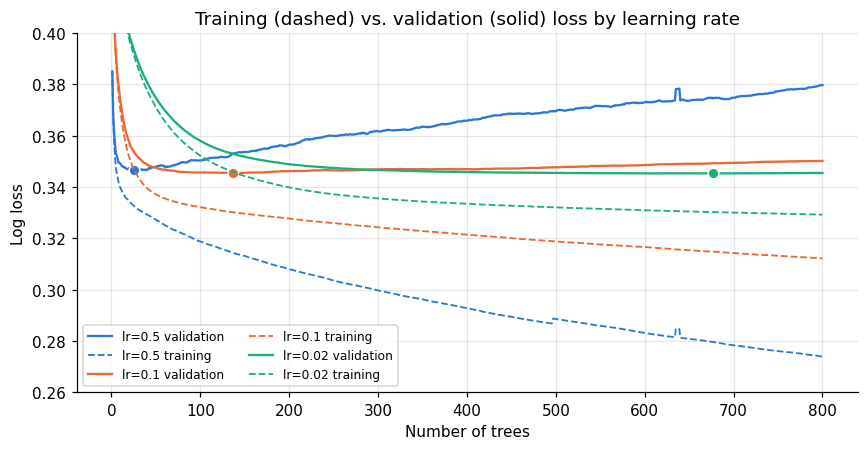

,best tree count,best val loss,val loss at 800,train loss at 800
0.50,25.0,0.3465,0.3797,0.2739
0.10,137.0,0.3454,0.3502,0.3122
0.02,677.0,0.3453,0.3455,0.3292


In [8]:
curves = {}
t0 = time.time()
for lr in [0.5, 0.1, 0.02]:
    g = GradientBoostingClassifier(n_estimators=800, learning_rate=lr, max_depth=3, random_state=SEED).fit(X_fit, y_fit)
    curves[lr] = {'train': [log_loss(y_fit, p[:, 1]) for p in g.staged_predict_proba(X_fit)],
                  'val': [log_loss(y_val, p[:, 1]) for p in g.staged_predict_proba(X_val)]}
print(f'{time.time()-t0:.0f}s')

fig, ax = plt.subplots(figsize=(8, 4.2))
for lr, c in zip(curves, [BLUE, ORANGE, GREEN]):
    v, t = curves[lr]['val'], curves[lr]['train']; b = int(np.argmin(v))
    ax.plot(range(1, 801), v, color=c, label=f'lr={lr} validation')
    ax.plot(range(1, 801), t, color=c, ls='--', lw=1.2, label=f'lr={lr} training')
    ax.plot(b + 1, v[b], 'o', color=c, ms=7, mec='white')
ax.set_ylim(0.26, 0.40); ax.set_xlabel('Number of trees'); ax.set_ylabel('Log loss')
ax.set_title('Training (dashed) vs. validation (solid) loss by learning rate'); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

pd.DataFrame({lr: {'best tree count': int(np.argmin(c['val'])) + 1, 'best val loss': min(c['val']),
                   'val loss at 800': c['val'][-1], 'train loss at 800': c['train'][-1]}
              for lr, c in curves.items()}).T.round(4)

Three things stand out:
- **All three learning rates reach the same best validation loss (about 0.345).** A smaller learning rate did not find a better model here; it found the same one more slowly.
- **Smaller learning rates need many more trees** to get there: about 25 trees at 0.5, about 140 at 0.1, and nearly 700 at 0.02.
- **Smaller learning rates are far more forgiving.** At 0.5, validation loss rises steadily after its best point while training loss keeps falling, which is overfitting. At 0.02 the validation curve is almost flat after its minimum, so stopping a bit early or late costs little.

In practice, the learning rate and the number of trees are tuned together. A moderate learning rate paired with **early stopping** (stop adding trees once validation loss stops improving) gets most of the benefit of a small learning rate at a fraction of the training time.

## 5. Tree depth
Depth sets how complex each weak learner can be: a depth-*d* tree can capture interactions among up to *d* features. A single deep tree can memorize a small dataset. With 1,000 samples, depth 10 allows up to $2^{10} = 1{,}024$ leaves, enough for one leaf per sample:

In [9]:
X_small, y_small = X_fit.iloc[:1000], y_fit.iloc[:1000]
rows = []
for d in [2, 5, 10, 15, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_small, y_small)
    rows.append({'max depth': d or 'unlimited', 'leaves': t.get_n_leaves(),
                 'train accuracy (1,000 rows)': accuracy_score(y_small, t.predict(X_small)),
                 'validation AUC': roc_auc_score(y_val, t.predict_proba(X_val)[:, 1])})
pd.DataFrame(rows).set_index('max depth').round(3)

,leaves,"train accuracy (1,000 rows)",validation AUC
max depth,,,
2,4,0.835,0.711
5,29,0.867,0.699
10,135,0.959,0.616
15,186,0.997,0.586
unlimited,188,1.000,0.590


The deep tree fits its 1,000 training rows almost perfectly but ranks unseen respondents much worse than a shallow one: it has learned this particular sample rather than the population. Boosting avoids this by combining many *shallow* trees. To find the right depth for the boosted trees, I compare training and validation AUC across depths, using early stopping so each depth gets its own best tree count:

4s


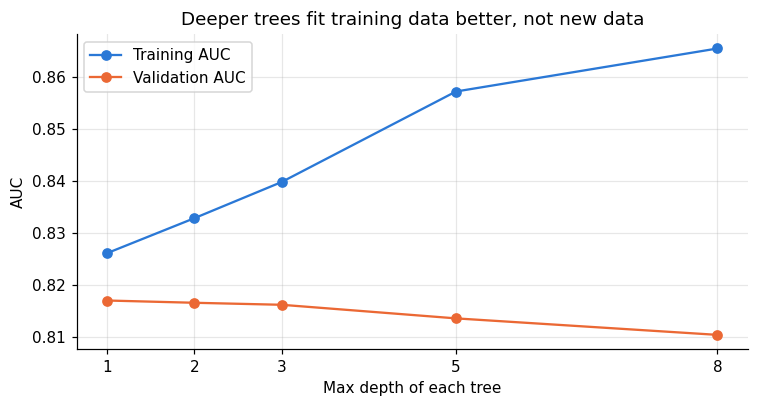

,trees used,train AUC,validation AUC,gap
depth,,,,
1,710,0.8262,0.8170,0.0091
2,361,0.8329,0.8166,0.0163
3,236,0.8398,0.8162,0.0236
5,142,0.8573,0.8136,0.0437
8,112,0.8655,0.8104,0.0551


In [10]:
rows = []
t0 = time.time()
for d in [1, 2, 3, 5, 8]:
    g = HistGradientBoostingClassifier(max_depth=d, learning_rate=0.1, max_iter=1000, early_stopping=True,
                                       validation_fraction=0.15, n_iter_no_change=30, random_state=SEED).fit(X_fit, y_fit)
    tr, va = roc_auc_score(y_fit, g.predict_proba(X_fit)[:, 1]), roc_auc_score(y_val, g.predict_proba(X_val)[:, 1])
    rows.append({'depth': d, 'trees used': g.n_iter_, 'train AUC': tr, 'validation AUC': va, 'gap': tr - va})
print(f'{time.time()-t0:.0f}s')
depth = pd.DataFrame(rows).set_index('depth')

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(depth.index, depth['train AUC'], marker='o', color=BLUE, label='Training AUC')
ax.plot(depth.index, depth['validation AUC'], marker='o', color=ORANGE, label='Validation AUC')
ax.set_xticks(depth.index); ax.set_xlabel('Max depth of each tree'); ax.set_ylabel('AUC')
ax.set_title('Deeper trees fit training data better, not new data'); ax.legend(); plt.tight_layout(); plt.show()
depth.round(4)

Training AUC climbs steadily with depth, but validation AUC is highest for the shallowest trees and slips as depth grows and the gap widens. Depths 1, 2 and 3 are within 0.001 of each other. Even stumps, which cannot represent any interaction between features, do as well as anything, given enough of them (early stopping used about 700). That says something about the data: diabetes risk in these 21 indicators is close to **additive**, so deeper trees mostly add the ability to fit noise. Shallow trees also need more rounds, which is the trade-off between depth and number of trees.

## 6. Regularization
Beyond the learning rate and depth, boosting can be regularized in three ways. To make the effects visible, I start from a model that deliberately overfits (depth 5, learning rate 0.1, 300 trees) and change one setting at a time:
1. **Penalize complexity:** limit the number of leaves per tree (`max_leaf_nodes`).
2. **Require a minimum number of samples per leaf** (`min_samples_leaf`), so no leaf can be fit to a handful of respondents.
3. **Subsample:** train each tree on a random fraction of the rows (stochastic gradient boosting).

In [11]:
base = dict(n_estimators=300, learning_rate=0.1, max_depth=5, random_state=SEED)
variants = {'baseline (depth 5)': {},
            '(1) max 8 leaves per tree': {'max_leaf_nodes': 8},
            '(2) min 200 samples per leaf': {'min_samples_leaf': 200},
            '(3) subsample 50% of rows': {'subsample': 0.5}}
rows = []
t0 = time.time()
for name, extra in variants.items():
    g = GradientBoostingClassifier(**{**base, **extra}).fit(X_fit, y_fit)
    tr, va = roc_auc_score(y_fit, g.predict_proba(X_fit)[:, 1]), roc_auc_score(y_val, g.predict_proba(X_val)[:, 1])
    rows.append({'model': name, 'train AUC': tr, 'validation AUC': va, 'gap': tr - va})
print(f'{time.time()-t0:.0f}s')
pd.DataFrame(rows).set_index('model').round(4)

26s


,train AUC,validation AUC,gap
model,,,
baseline (depth 5),0.8879,0.8057,0.0821
(1) max 8 leaves per tree,0.8491,0.8148,0.0343
(2) min 200 samples per leaf,0.8598,0.8125,0.0473
(3) subsample 50% of rows,0.8888,0.8033,0.0855


Limiting leaves and requiring larger leaves both shrink the train–validation gap, because each tree is less able to fit small pockets of noise. Subsampling barely changed the result here: with 32,000 rows, each 50% subsample is still large and representative, so the trees do not become meaningfully more varied. Subsampling helps most on smaller or noisier data, and it also speeds up training.

The histogram-based booster used next also offers an **L2 penalty** on leaf values (`l2_regularization`), which shrinks large corrections toward zero. I include it in the grid search below.

## 7. Tuning with early stopping and grid search
Putting it together, I grid-search scikit-learn's `HistGradientBoostingClassifier`, which bins features into histograms and trains much faster than the classic version (the same idea behind LightGBM). Every candidate uses:
- **early stopping**: 15% of each training fold is held out, and training stops after 30 trees without improvement, so the number of trees is chosen automatically;
- **balanced class weights**, so the 15.8% positive class counts as much as the majority;
- **3-fold stratified CV AUC** as the selection score.

The grid is learning rate {0.03, 0.1, 0.3} × max depth {2, 3, 5, 8} × L2 penalty {0, 1}: 24 combinations.

In [12]:
grid = {'learning_rate': [0.03, 0.1, 0.3], 'max_depth': [2, 3, 5, 8], 'l2_regularization': [0.0, 1.0]}
hgb = HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.15, n_iter_no_change=30,
                                     scoring='loss', class_weight='balanced', random_state=SEED)
gs = GridSearchCV(hgb, grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring='roc_auc',
                  n_jobs=-1, return_train_score=True)
t0 = time.time(); gs.fit(X_train, y_train); print(f'Grid search: {time.time()-t0:.0f}s')
best = gs.best_estimator_
print('Best parameters:', gs.best_params_, f'| CV AUC {gs.best_score_:.4f} | trees used {best.n_iter_}')

Grid search: 13s
Best parameters: {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_depth': 2} | CV AUC 0.8225 | trees used 146


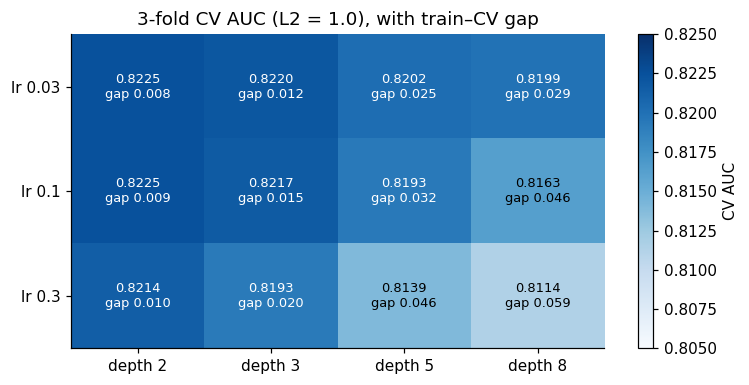

Effect of the L2 penalty (CV AUC, L2=1 minus L2=0), by cell:
  range -0.0008 to +0.0025


In [13]:
cvr = pd.DataFrame(gs.cv_results_)
cvr['gap'] = cvr['mean_train_score'] - cvr['mean_test_score']
sub = cvr[cvr['param_l2_regularization'] == 1.0]
M = sub.pivot(index='param_learning_rate', columns='param_max_depth', values='mean_test_score')
G = sub.pivot(index='param_learning_rate', columns='param_max_depth', values='gap')

fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(M.values, cmap='Blues', vmin=0.805, vmax=0.825, aspect='auto')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f'{M.values[i, j]:.4f}\ngap {G.values[i, j]:.3f}', ha='center', va='center', fontsize=8.5,
                color='white' if M.values[i, j] > 0.818 else 'black')
ax.set_xticks(range(M.shape[1]), [f'depth {d}' for d in M.columns]); ax.set_yticks(range(M.shape[0]), [f'lr {l}' for l in M.index])
ax.grid(False); ax.set_title('3-fold CV AUC (L2 = 1.0), with train–CV gap'); fig.colorbar(im, ax=ax, label='CV AUC')
plt.tight_layout(); plt.show()

print('Effect of the L2 penalty (CV AUC, L2=1 minus L2=0), by cell:')
l2 = cvr.pivot_table(index=['param_learning_rate', 'param_max_depth'], columns='param_l2_regularization', values='mean_test_score')
print(f"  range {(l2[1.0] - l2[0.0]).min():+.4f} to {(l2[1.0] - l2[0.0]).max():+.4f}")

The grid confirms the experiments above. The best model uses the **shallowest trees** (depth 2) with a moderate learning rate, and early stopping chose about 150 trees for it. Moving down or right in the grid (higher learning rate, deeper trees) lowers CV AUC and widens the train–CV gap, from under 0.01 at depth 2 to about 0.06 at depth 8 with learning rate 0.3. The L2 penalty changes CV AUC by at most about 0.002 in any cell, because depth limits and early stopping already control complexity.

## 8. Final model on the test set
I choose the cutoff that maximizes F1 using out-of-fold predictions on the training set, then evaluate the tuned model once on the untouched test set. Logistic regression (balanced weights) is refit on the identical split as a baseline.

In [14]:
oof = cross_val_predict(HistGradientBoostingClassifier(**best.get_params()), X_train, y_train,
                        cv=StratifiedKFold(3, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
cut = thr[np.argmax((2 * prec * rec / (prec + rec + 1e-12))[:-1])]

p_gb = best.predict_proba(X_test)[:, 1]
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')).fit(X_train, y_train)
p_lr = logreg.predict_proba(X_test)[:, 1]

def report(y_true, proba, c):
    pred = proba >= c
    return {'AUC': roc_auc_score(y_true, proba), 'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred), 'recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred)}
pd.DataFrame({'Gradient boosting, cutoff 0.5': report(y_test, p_gb, 0.5),
              f'Gradient boosting, cutoff {cut:.2f}': report(y_test, p_gb, cut),
              'Logistic regression, cutoff 0.5': report(y_test, p_lr, 0.5)}).T.round(3)

,AUC,accuracy,precision,recall,F1
"Gradient boosting, cutoff 0.5",0.818,0.726,0.337,0.764,0.468
"Gradient boosting, cutoff 0.60",0.818,0.784,0.388,0.650,0.486
"Logistic regression, cutoff 0.5",0.812,0.731,0.340,0.750,0.468


In [15]:
print(f"Training AUC {roc_auc_score(y_train, best.predict_proba(X_train)[:, 1]):.3f} vs. test AUC {roc_auc_score(y_test, p_gb):.3f}")

Training AUC 0.828 vs. test AUC 0.818


Test AUC is within about 0.01 of training AUC, so the tuned model is not overfitting. Because the model was trained with balanced class weights, the default 0.5 cutoff already catches most diabetic respondents. The F1-tuned cutoff trades some of that recall for better precision and gives the best F1 of any model in this project. Gradient boosting edges out logistic regression on AUC.

Which features is the model relying on? **Permutation importance** shuffles one feature at a time on the test set and measures how much AUC drops. Unlike the built-in importance, which counts how often a feature is used for splitting, it measures how much predictions actually depend on the feature.

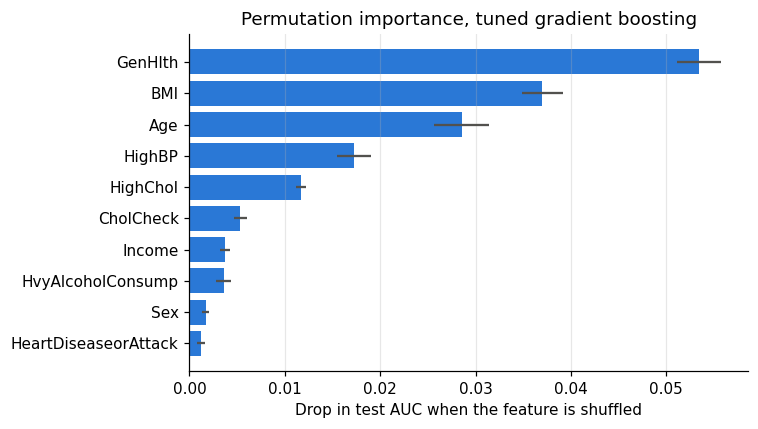

In [16]:
pi = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({'mean AUC drop': pi.importances_mean, 'std': pi.importances_std}, index=X_test.columns)
top = imp.sort_values('mean AUC drop').tail(10)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top['mean AUC drop'], xerr=top['std'], color=BLUE, error_kw={'ecolor': '#52514e'})
ax.set_xlabel('Drop in test AUC when the feature is shuffled'); ax.set_title('Permutation importance, tuned gradient boosting')
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

General health, BMI, age, high blood pressure and high cholesterol dominate, the same top five as logistic regression's coefficients and random forest's importances in earlier weeks. Three model families agreeing on the same drivers is good evidence that these are real signals in the data, not artifacts of one model.

## 9. Does more data help? Full BRFSS
The gap between gradient boosting and logistic regression on the 10,000-row test set is small enough that it could be noise. To check, I retrain both with the same settings on the **full 253,680 rows** (80/20 split) and bootstrap the test set 300 times to get a confidence interval for the AUC difference.

In [17]:
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
t0 = time.time()
gb_full = HistGradientBoostingClassifier(**best.get_params()).fit(Xf_tr, yf_tr)
lr_full = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')).fit(Xf_tr, yf_tr)
pg, pl, yv = gb_full.predict_proba(Xf_te)[:, 1], lr_full.predict_proba(Xf_te)[:, 1], yf_te.values

rng = np.random.default_rng(SEED); diffs = []
for _ in range(300):
    i = rng.integers(0, len(yv), len(yv))
    diffs.append(roc_auc_score(yv[i], pg[i]) - roc_auc_score(yv[i], pl[i]))
print(f'{time.time()-t0:.0f}s')
print(f'Gradient boosting AUC {roc_auc_score(yv, pg):.4f} (trees used: {gb_full.n_iter_})')
print(f'Logistic regression AUC {roc_auc_score(yv, pl):.4f}')
print(f'Difference 95% bootstrap CI: [{np.percentile(diffs, 2.5):.4f}, {np.percentile(diffs, 97.5):.4f}]')

6s
Gradient boosting AUC 0.8241 (trees used: 318)
Logistic regression AUC 0.8176
Difference 95% bootstrap CI: [0.0054, 0.0077]


With the full dataset, gradient boosting's edge is small but clearly real: the whole confidence interval is above zero. Early stopping also let the model use about twice as many trees as on the 40,000-row sample, because more data supports more corrections before they start fitting noise. A linear model cannot use extra data this way, since its shape is fixed.

## 10. Dataset A: Health & Lifestyle
Earlier weeks found no recoverable signal in Dataset A. Gradient boosting is a strong test, since it can find nonlinear patterns and interactions that linear models miss. Early stopping also acts as a built-in diagnostic: if no tree improves validation loss, training stops almost immediately.

In [18]:
la = life.drop(columns=['id']).assign(gender=lambda d: (d.gender == 'Male').astype(int))
XA = la.drop(columns=['disease_risk']); yA = la['disease_risk']
XA_tr, XA_te, yA_tr, yA_te = train_test_split(XA, yA, test_size=0.2, stratify=yA, random_state=SEED)
clfA = HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=SEED).fit(XA_tr, yA_tr)

XB = la.drop(columns=['bmi', 'disease_risk']); yB = la['bmi']
XB_tr, XB_te, yB_tr, yB_te = train_test_split(XB, yB, test_size=0.2, random_state=SEED)
regA = HistGradientBoostingRegressor(max_iter=1000, early_stopping=True, random_state=SEED).fit(XB_tr, yB_tr)

pd.DataFrame({'disease_risk (classification)': {'trees before early stop': clfA.n_iter_,
                  'train score': roc_auc_score(yA_tr, clfA.predict_proba(XA_tr)[:, 1]),
                  'test score': roc_auc_score(yA_te, clfA.predict_proba(XA_te)[:, 1]), 'score type': 'AUC'},
              'BMI (regression)': {'trees before early stop': regA.n_iter_,
                  'train score': r2_score(yB_tr, regA.predict(XB_tr)),
                  'test score': r2_score(yB_te, regA.predict(XB_te)), 'score type': 'R²'}}).T

,trees before early stop,train score,test score,score type
disease_risk (classification),15,0.58968,0.493271,AUC
BMI (regression),24,0.011854,-0.001624,R²


Early stopping ended training after only a handful of trees for both targets, and test performance is at chance (AUC about 0.49, R² slightly below zero). The small rise in training AUC is the model fitting noise in the training rows, and none of it carries over to the test set. Even a flexible nonlinear ensemble finds nothing, which is consistent with Dataset A's columns having been generated independently of each other.

## 11. Summary
| Topic | Finding |
|---|---|
| Method | Reproduced boosting by hand (stumps fit to residuals, scaled by the learning rate); matches scikit-learn exactly. |
| vs. random forest | Random forest levels off as trees are added; boosting reaches lower loss but overfits if trees keep being added at a high learning rate. |
| Learning rate | 0.5, 0.1 and 0.02 all reach the same best validation loss (~0.345), needing ~25, ~140 and ~700 trees. Smaller rates are slower but much more forgiving about when to stop. |
| Tree depth | Depths 1–3 tie for best. Deeper trees raise training AUC and lower validation AUC. Shallow optimum means risk is nearly additive. |
| Regularization | Leaf limits and minimum leaf size shrink the train–validation gap; row subsampling and L2 had little effect here. |
| Tuned model | Depth 2, lr 0.1, L2 1, early stopping at ~150 trees. Best F1 of any model in the project, with test AUC within 0.01 of training AUC. |
| More data | On all 253,680 rows, gradient boosting beats logistic regression by a small margin whose 95% CI excludes zero. |
| Dataset A | Early stopping halts within a few trees; test AUC ≈ 0.49 and R² ≈ 0. No signal. |

**Sources:** Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics, 29*(5); scikit-learn User Guide, *Ensembles: Gradient boosting* (https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting); Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *NeurIPS 30*; Hastie, Tibshirani & Friedman (2009), *The Elements of Statistical Learning*, Ch. 10.